# 05 · Deep Learning Models
## Kenyan Sign Language (KSL) Recognition with Deep Learning

| | |
|---|---|
| **Course** | DSA 4050-XA: Deep Learning, USIU-Africa (Fall 2026) |
| **Student** | Selmah Tzindori (669602) |
| **Notebook** | `05_deep_learning.ipynb` |
| **Term paper part** | (c) Undertake ML algorithms (consider accuracy) and test various ML training |

### Objective
Train **convolutional neural networks (CNNs)**, which learn their own image features instead of relying on hand-crafted ones like HOG, and compare them with the best classic model from notebook 04 (**HOG + SVM, 60.0% test accuracy**).

| # | Model | Approach |
|---|---|---|
| 1 | **Custom CNN** | Trained **from scratch** on our 4,362 training images |
| 2 | **MobileNetV2** | **Transfer learning**: a network pretrained on ImageNet (1.3 million photos), adapted to KSL |
| 3 | **EfficientNetB0** | Transfer learning with a newer, more accurate architecture |

### Inputs
- `data/processed/ksl_224.zip` and `catalogue_split.csv` (from notebook 03)

### Outputs
| File | Location | Purpose |
|---|---|---|
| `cnn_scratch.keras`, `mobilenetv2.keras`, `efficientnetb0.keras`, `efficientnetb0_ft2.keras` | `models/` | Trained models |
| `dl_best.keras` | `models/` | Best deep-learning model (by validation accuracy) for evaluation and the dashboard |
| 4 rows in `experiments.csv` | `outputs/` | Accuracy, macro-F1, size and speed of each model |
| `history_*.csv`, `history_*.png` | `outputs/` | Training curves |
| `05_*.png`, `05_*.csv` | `outputs/` | Augmentation examples, comparison chart and table |

**Runtime:** about 30–45 minutes on a T4 GPU. Each model is saved as soon as it finishes; if Colab disconnects, re-running skips models that are already trained.

## 0 · Setup

In [1]:
# =============================================================================
# STANDARD SETUP CELL
# =============================================================================
from google.colab import drive
drive.mount("/content/drive")

import sys
sys.path.insert(0, "/content/drive/MyDrive/DSA4050/ksl-recognition/src")

import importlib
import ksl_utils as ku
importlib.reload(ku)
ku.set_seed()

NOTEBOOK = "05_deep_learning"
PATHS = ku.PATHS
print("Project root:", ku.PROJECT_ROOT)

Mounted at /content/drive
Random seed set to 42
Project root: /content/drive/MyDrive/DSA4050/ksl-recognition


In [2]:
# Libraries used in this notebook
import os
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
from keras import layers
from sklearn.metrics import accuracy_score, f1_score

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "font.size": 11})

print("TensorFlow", tf.__version__, "| Keras", keras.__version__)
print("GPU:", tf.config.list_physical_devices("GPU") or "none: switch to T4 GPU (Runtime -> Change runtime type)")

TensorFlow 2.21.0 | Keras 3.13.2
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [3]:
# Restore the 224x224 images and load the split catalogue
PROC_DIR = Path(ku.restore_processed_data())
cat = ku.load_split_catalogue()
CLASS_NAMES = ku.load_class_names()
N_CLASSES = len(CLASS_NAMES)
print(cat["split"].value_counts().reindex(["train", "val", "test"]).to_string())

Processed data restored to /content/ksl_224 in 2s
split
train    4362
val       935
test      941


### 0.1 · Training settings
| Setting | Value | Why |
|---|---|---|
| Image size | 224×224×3 (colour) | Native input size of the pretrained models |
| Batch size | 32 | Fits comfortably in T4 memory |
| Optimiser | Adam | Standard adaptive optimiser |
| Loss | Sparse categorical cross-entropy | Multi-class labels stored as integers 0–8 |
| Early stopping | Stop when validation accuracy has not improved for several epochs; keep the best weights | Prevents overfitting and wasted time |
| `RETRAIN` | `False` | If a model file already exists on Drive, load it instead of training again |

In [4]:
IMG_SIZE = 224
BATCH = 32
RETRAIN = False          # set True to force every model to train again
AUTOTUNE = tf.data.AUTOTUNE

## 1 · Input pipeline
`tf.data` reads each JPEG, decodes it to a 224×224×3 array of pixel values (0–255) and batches the images. Decoded images are **cached in memory** after the first epoch, so later epochs run much faster. Training data is **shuffled** every epoch; validation and test data keep a fixed order.

Each model contains its own pixel-scaling step, so every model takes the same raw 0–255 input. This also makes the saved models easy to use in the dashboard.

In [5]:
def make_dataset(split: str, shuffle: bool) -> tf.data.Dataset:
    """Dataset of (image uint8 224x224x3, label int) pairs for one split."""
    sub = cat[cat["split"] == split]
    paths = [str(PROC_DIR / f) for f in sub["proc_file"]]
    labels = sub["label_idx"].to_numpy()

    def load(path, label):
        img = tf.io.decode_jpeg(tf.io.read_file(path), channels=3)
        img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))           # no-op for 224 images, safety
        return tf.cast(img, tf.uint8), label

    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    ds = ds.map(load, num_parallel_calls=AUTOTUNE).cache()          # decode once, keep in RAM
    if shuffle:
        ds = ds.shuffle(len(sub), seed=ku.SEED, reshuffle_each_iteration=True)
    return ds.batch(BATCH).prefetch(AUTOTUNE)

train_ds = make_dataset("train", shuffle=True)
val_ds = make_dataset("val", shuffle=False)
test_ds = make_dataset("test", shuffle=False)
y_test = cat.loc[cat["split"] == "test", "label_idx"].to_numpy()
print("Batches -> train:", len(train_ds), "| val:", len(val_ds), "| test:", len(test_ds))

Batches -> train: 137 | val: 30 | test: 30


## 2 · Data augmentation
Each training image is **randomly altered every epoch**, so the model never sees exactly the same picture twice. This imitates new signers, camera angles and lighting, and is the main defence against the overfitting seen in notebook 04 (100% train vs 60% test).

| Augmentation | Setting | Imitates |
|---|---|---|
| Horizontal flip | 50% chance | Left-handed signers (KSL signs are mirrored by left-handed signers) |
| Rotation | up to ±10° | Tilted phone |
| Zoom | up to ±15% | Phone closer or further away |
| Translation | up to ±10% | Signer off-centre |
| Brightness and contrast | up to ±20% | Different lighting (and the dim photos found in notebook 02) |

Augmentation is part of each model but is **only active during training**; validation, test and dashboard predictions use the unaltered image.

Figure saved -> /content/drive/MyDrive/DSA4050/ksl-recognition/outputs/figures/05_augmentation_examples.png


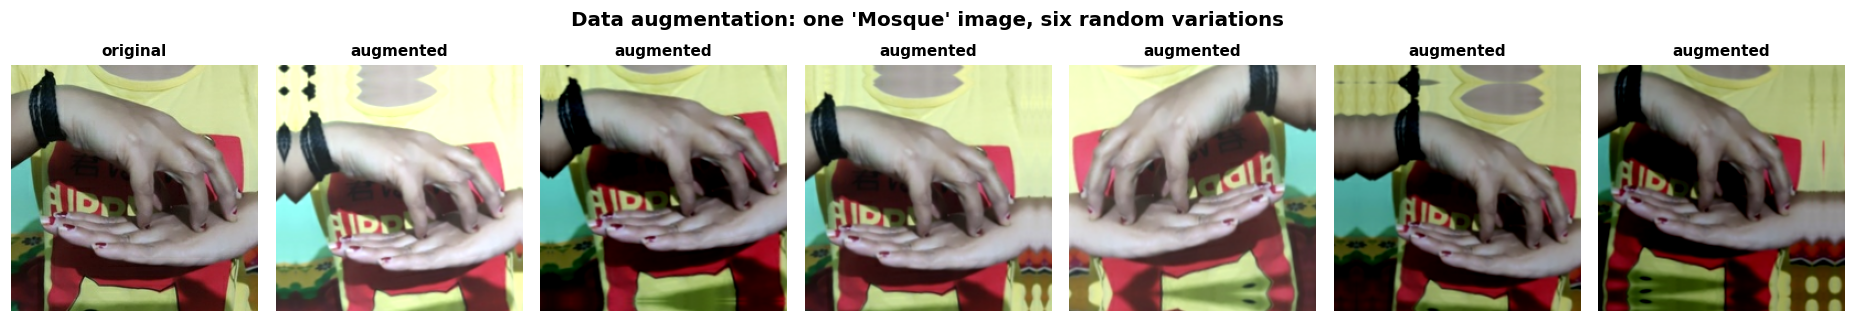

In [6]:
augment = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(10 / 360),                  # fraction of a full circle -> ±10 degrees
    layers.RandomZoom(0.15),
    layers.RandomTranslation(0.10, 0.10),
    layers.RandomBrightness(0.2, value_range=(0, 255)),
    layers.RandomContrast(0.2),
], name="augmentation")

# Show 6 random augmented versions of one training image
images, labels = next(iter(train_ds))
img = tf.cast(images[:1], tf.float32)
fig, axes = plt.subplots(1, 7, figsize=(17, 3))
axes[0].imshow(images[0].numpy()); axes[0].set_title("original", fontsize=10)
for ax in axes[1:]:
    ax.imshow(np.clip(augment(img, training=True)[0].numpy(), 0, 255).astype("uint8"))
    ax.set_title("augmented", fontsize=10)
for ax in axes:
    ax.axis("off")
fig.suptitle(f"Data augmentation: one '{CLASS_NAMES[int(labels[0])]}' image, six random variations",
             fontsize=13, fontweight="bold")
fig.tight_layout()
ku.save_figure(fig, "05_augmentation_examples", NOTEBOOK, caption="One training image and six randomly augmented versions.")
plt.show()

## 3 · Shared training and evaluation helpers
- `train_stage()` trains for up to *n* epochs with **early stopping** (keeps the best weights by validation accuracy), **learning-rate reduction** when progress stalls, and a **checkpoint** of the best weights on Drive.
- `evaluate_and_log()` measures test accuracy, macro-F1, model size and prediction speed, and adds a row to `experiments.csv`, the same table as the classic models, so all results are directly comparable.

In [7]:
def compile_model(model, lr):
    model.compile(optimizer=keras.optimizers.Adam(lr),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])


def train_stage(model, name: str, epochs: int, lr: float, patience: int):
    """Compile and train one stage; returns the Keras History object."""
    compile_model(model, lr)
    callbacks = [
        keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=patience,
                                      restore_best_weights=True, verbose=1),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5,
                                          patience=max(2, patience // 2), min_lr=1e-7, verbose=1),
        keras.callbacks.ModelCheckpoint(os.path.join(PATHS["checkpoints"], f"{name}_best.keras"),
                                        monitor="val_accuracy", save_best_only=True),
    ]
    return model.fit(train_ds, validation_data=val_ds, epochs=epochs, callbacks=callbacks, verbose=2)


def merge_histories(*histories) -> dict:
    """Join the epoch-by-epoch logs of several training stages into one."""
    merged = {}
    for h in histories:
        for k, v in h.history.items():
            merged.setdefault(k, []).extend([float(x) for x in v])
    return merged


def predict_probs(model, ds):
    return model.predict(ds, verbose=0)


def evaluate_and_log(model, name: str, train_time_s: float, params: dict, notes: str = "") -> dict:
    """Test-set metrics + size/speed, logged to experiments.csv."""
    start = time.time()
    probs = predict_probs(model, test_ds)
    pred_ms = 1000 * (time.time() - start) / len(y_test)
    pred = probs.argmax(axis=1)
    val_acc = model.evaluate(val_ds, verbose=0)[1]
    train_acc = model.evaluate(train_ds.take(40), verbose=0)[1]        # ~1,280 images, augmentation off
    metrics = {"train_accuracy": round(float(train_acc), 4),
               "val_accuracy": round(float(val_acc), 4),
               "test_accuracy": round(float(accuracy_score(y_test, pred)), 4),
               "test_macro_f1": round(float(f1_score(y_test, pred, average="macro")), 4),
               "fit_time_s": round(float(train_time_s), 1),
               "predict_ms_per_image": round(float(pred_ms), 3),
               "n_params_millions": round(model.count_params() / 1e6, 2)}
    ku.log_experiment(name, "deep_learning", metrics, NOTEBOOK, params=params, notes=notes)
    np.save(os.path.join(PATHS["logs"], f"test_probs_{name}.npy"), probs)   # reused in notebook 06
    return metrics


def already_trained(name: str) -> bool:
    return (not RETRAIN) and os.path.exists(ku.model_path(name))


ALL_RESULTS = {}

## 4 · Model 1: custom CNN from scratch
A compact CNN with **four convolution blocks**. Each block learns filters (small pattern detectors) and halves the image size, so early blocks detect edges and textures while later blocks detect larger shapes such as fingers and hands.

```
input 224×224×3 → augmentation → rescale to 0–1
→ [Conv 32 → BatchNorm → ReLU → MaxPool]
→ [Conv 64 → BatchNorm → ReLU → MaxPool]
→ [Conv 128 → BatchNorm → ReLU → MaxPool]
→ [Conv 256 → BatchNorm → ReLU → MaxPool]
→ Global average pooling → Dropout 0.4 → Dense 9 (softmax)
```
- **Batch normalisation** stabilises and speeds up training.
- **Global average pooling** and **dropout** keep the number of weights low and reduce overfitting.
- Trained for up to 60 epochs with learning rate 0.001.

In [8]:
def build_scratch_cnn() -> keras.Model:
    inputs = keras.Input((IMG_SIZE, IMG_SIZE, 3))
    x = augment(inputs)
    x = layers.Rescaling(1 / 255)(x)
    for filters in [32, 64, 128, 256]:
        x = layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation("relu")(x)
        x = layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation("relu")(x)
        x = layers.MaxPooling2D()(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.4)(x)
    outputs = layers.Dense(N_CLASSES, activation="softmax")(x)
    return keras.Model(inputs, outputs, name="cnn_scratch")

NAME = "cnn_scratch"
if already_trained(NAME):
    model = keras.models.load_model(ku.model_path(NAME))
    print(f"Loaded existing {NAME}; training skipped")
    train_time = float(pd.read_csv(ku.EXPERIMENTS_FILE).set_index("model").loc[NAME, "fit_time_s"])
else:
    keras.utils.set_random_seed(ku.SEED)
    model = build_scratch_cnn()
    model.summary(line_length=90)
    start = time.time()
    hist = train_stage(model, NAME, epochs=60, lr=1e-3, patience=10)
    train_time = time.time() - start
    model.save(ku.model_path(NAME))
    history = merge_histories(hist)
    ku.save_history(history, NAME, NOTEBOOK)
    ku.plot_history(history, NAME, NOTEBOOK)
    plt.show()

ALL_RESULTS[NAME] = evaluate_and_log(model, NAME, train_time,
                                     params={"epochs_max": 60, "lr": 1e-3, "augmentation": True})
ALL_RESULTS[NAME]

Loaded existing cnn_scratch; training skipped
Experiment logged: cnn_scratch -> {'train_accuracy': 0.9328, 'val_accuracy': 0.8578, 'test_accuracy': 0.8427, 'test_macro_f1': 0.8431, 'fit_time_s': 2506.0, 'predict_ms_per_image': 5.448, 'n_params_millions': 1.18}


{'train_accuracy': 0.9328,
 'val_accuracy': 0.8578,
 'test_accuracy': 0.8427,
 'test_macro_f1': 0.8431,
 'fit_time_s': 2506.0,
 'predict_ms_per_image': 5.448,
 'n_params_millions': 1.18}

**Interpretation:** the CNN trained from scratch reaches **84.3% test accuracy (macro-F1 0.843)**, **+24.3 points above HOG + SVM (60.0%)**. Training and validation accuracy rise together (93.4% vs 85.8% at the end), so augmentation kept overfitting far below the classic models (100% vs 60%). Validation accuracy was **still improving at epoch 60**, so the network had not fully converged. It is the smallest model (1.18M weights) and the fastest at prediction (2.7 ms per image), but by far the slowest to train (about 42 minutes).

## 5 · Transfer learning
Training a deep network from scratch needs far more than 4,362 images. **Transfer learning** starts from a network already trained on **ImageNet** (1.3 million photos, 1,000 everyday object classes). Its early and middle layers already detect edges, textures, skin, fingers and shapes; we only need to teach it which combinations mean which KSL sign.

Two training stages:
1. **Feature extraction:** the pretrained base is **frozen** (its weights do not change) and only a new classification head (pooling → dropout → 9-way dense layer) is trained, with learning rate 0.001.
2. **Fine-tuning:** the **top layers of the base are unfrozen** and the whole network is trained further with a **very small learning rate (0.00001)**, so the pretrained features adapt gently to hand signs without being destroyed. Batch-normalisation layers stay frozen, as recommended for fine-tuning.

In [9]:
def build_transfer_model(base_fn, scaling_layer, name: str):
    """Pretrained base (frozen) + new 9-class head. Returns (model, base)."""
    base = base_fn(include_top=False, weights="imagenet", input_shape=(IMG_SIZE, IMG_SIZE, 3))
    base.trainable = False
    inputs = keras.Input((IMG_SIZE, IMG_SIZE, 3))
    x = augment(inputs)
    if scaling_layer is not None:
        x = scaling_layer(x)
    x = base(x, training=False)                 # keep batch-norm statistics fixed
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(N_CLASSES, activation="softmax")(x)
    return keras.Model(inputs, outputs, name=name), base


def unfreeze_top(base, n_layers: int):
    """Make the last n layers of the base trainable, except batch-normalisation layers."""
    base.trainable = True
    for layer in base.layers[:-n_layers]:
        layer.trainable = False
    for layer in base.layers:
        if isinstance(layer, layers.BatchNormalization):
            layer.trainable = False


def run_transfer(name, base_fn, scaling_layer, n_unfreeze, head_epochs=15, ft_epochs=25):
    """Full two-stage transfer-learning run (or load if already trained)."""
    if already_trained(name):
        model = keras.models.load_model(ku.model_path(name))
        print(f"Loaded existing {name}; training skipped")
        train_time = float(pd.read_csv(ku.EXPERIMENTS_FILE).set_index("model").loc[name, "fit_time_s"])
    else:
        keras.utils.set_random_seed(ku.SEED)
        model, base = build_transfer_model(base_fn, scaling_layer, name)
        print(f"{name}: {model.count_params() / 1e6:.2f}M parameters, base has {len(base.layers)} layers")
        start = time.time()
        print("\n--- Stage 1: train the new head (base frozen) ---")
        h1 = train_stage(model, name, epochs=head_epochs, lr=1e-3, patience=5)
        print(f"\n--- Stage 2: fine-tune the top {n_unfreeze} layers of the base ---")
        unfreeze_top(base, n_unfreeze)
        h2 = train_stage(model, name, epochs=ft_epochs, lr=1e-5, patience=7)
        train_time = time.time() - start
        model.save(ku.model_path(name))
        history = merge_histories(h1, h2)
        ku.save_history(history, name, NOTEBOOK)
        fig = ku.plot_history(history, name, NOTEBOOK)
        for ax in fig.axes:                      # mark where fine-tuning started
            ax.axvline(len(h1.history["loss"]) - 0.5, color="grey", linestyle=":")
        fig.savefig(os.path.join(PATHS["figures"], f"history_{name}.png"), dpi=300, bbox_inches="tight")
        plt.show()
    params = {"head_epochs_max": head_epochs, "ft_epochs_max": ft_epochs, "lr_head": 1e-3,
              "lr_finetune": 1e-5, "unfrozen_layers": n_unfreeze, "augmentation": True}
    return model, evaluate_and_log(model, name, train_time, params=params)

### 5.1 · Model 2: MobileNetV2
A lightweight network (about 2.3 million weights) designed for **phones**, a good fit for a sign-recognition app. It expects pixel values in the range −1 to 1, so a rescaling layer is added. The top 40 layers are fine-tuned.

In [10]:
NAME = "mobilenetv2"
mobilenet, ALL_RESULTS[NAME] = run_transfer(
    NAME, keras.applications.MobileNetV2,
    scaling_layer=layers.Rescaling(1 / 127.5, offset=-1),       # 0..255 -> -1..1
    n_unfreeze=40)
ALL_RESULTS[NAME]

Loaded existing mobilenetv2; training skipped
Experiment logged: mobilenetv2 -> {'train_accuracy': 0.9344, 'val_accuracy': 0.8439, 'test_accuracy': 0.8162, 'test_macro_f1': 0.8174, 'fit_time_s': 446.9, 'predict_ms_per_image': 4.237, 'n_params_millions': 2.27}


{'train_accuracy': 0.9344,
 'val_accuracy': 0.8439,
 'test_accuracy': 0.8162,
 'test_macro_f1': 0.8174,
 'fit_time_s': 446.9,
 'predict_ms_per_image': 4.237,
 'n_params_millions': 2.27}

**Interpretation:** with the base frozen, MobileNetV2 plateaus at about **68% validation accuracy**: generic ImageNet features alone do not separate the signs well. **Fine-tuning (after the dotted line) adds about 16 points**, reaching 84.4% validation and **81.6% test accuracy**, slightly below the scratch CNN. It trained in about 7.5 minutes, roughly **5.6× faster** than the scratch CNN.

### 5.2 · Model 3: EfficientNetB0
A newer architecture that balances network depth, width and resolution for higher accuracy at a similar size (about 4 million weights). It includes its own input scaling, so it takes 0–255 pixels directly. The top 40 layers are fine-tuned.

In [11]:
NAME = "efficientnetb0"
effnet, ALL_RESULTS[NAME] = run_transfer(
    NAME, keras.applications.EfficientNetB0,
    scaling_layer=None,                                         # built-in preprocessing
    n_unfreeze=40)
ALL_RESULTS[NAME]

Loaded existing efficientnetb0; training skipped
Experiment logged: efficientnetb0 -> {'train_accuracy': 0.9039, 'val_accuracy': 0.8642, 'test_accuracy': 0.8491, 'test_macro_f1': 0.8493, 'fit_time_s': 604.3, 'predict_ms_per_image': 8.037, 'n_params_millions': 4.06}


{'train_accuracy': 0.9039,
 'val_accuracy': 0.8642,
 'test_accuracy': 0.8491,
 'test_macro_f1': 0.8493,
 'fit_time_s': 604.3,
 'predict_ms_per_image': 8.037,
 'n_params_millions': 4.06}

**Interpretation:** EfficientNetB0 is the best of the first three deep models: **86.4% validation and 84.9% test accuracy** (macro-F1 0.849), 3.3 points above MobileNetV2, trained in about 10 minutes. Its training and validation curves stay **almost on top of each other** (no overfitting) and were **still rising at the last fine-tuning epoch**, and only the top 40 of its 238 layers were adapted. This suggests it was **under-trained** rather than at its limit, which Section 6 tests.

## 6 · Extended fine-tuning of EfficientNetB0
The EfficientNetB0 curves were still rising when training stopped, with no sign of overfitting. A short extra stage tests whether more adaptation helps:
- start from the trained `efficientnetb0` model;
- **unfreeze the top 100 layers** (instead of 40), batch-normalisation layers still frozen;
- train up to 40 more epochs at learning rate 0.00001, with early stopping.

It is saved as a separate model, `efficientnetb0_ft2`, so both versions can be compared; the best one is still chosen by validation accuracy.

Trainable weights now: 2.05M
Epoch 1/40
137/137 - 33s - 240ms/step - accuracy: 0.8686 - loss: 0.3753 - val_accuracy: 0.8610 - val_loss: 0.4114 - learning_rate: 1.0000e-05
Epoch 2/40
137/137 - 14s - 104ms/step - accuracy: 0.8709 - loss: 0.3688 - val_accuracy: 0.8642 - val_loss: 0.3994 - learning_rate: 1.0000e-05
Epoch 3/40
137/137 - 15s - 109ms/step - accuracy: 0.8712 - loss: 0.3634 - val_accuracy: 0.8652 - val_loss: 0.4052 - learning_rate: 1.0000e-05
Epoch 4/40
137/137 - 13s - 98ms/step - accuracy: 0.8755 - loss: 0.3617 - val_accuracy: 0.8631 - val_loss: 0.3977 - learning_rate: 1.0000e-05
Epoch 5/40
137/137 - 14s - 99ms/step - accuracy: 0.8744 - loss: 0.3594 - val_accuracy: 0.8620 - val_loss: 0.3971 - learning_rate: 1.0000e-05
Epoch 6/40
137/137 - 14s - 100ms/step - accuracy: 0.8801 - loss: 0.3465 - val_accuracy: 0.8642 - val_loss: 0.3946 - learning_rate: 1.0000e-05
Epoch 7/40
137/137 - 15s - 109ms/step - accuracy: 0.8826 - loss: 0.3393 - val_accuracy: 0.8674 - val_loss: 0.3942 - learn

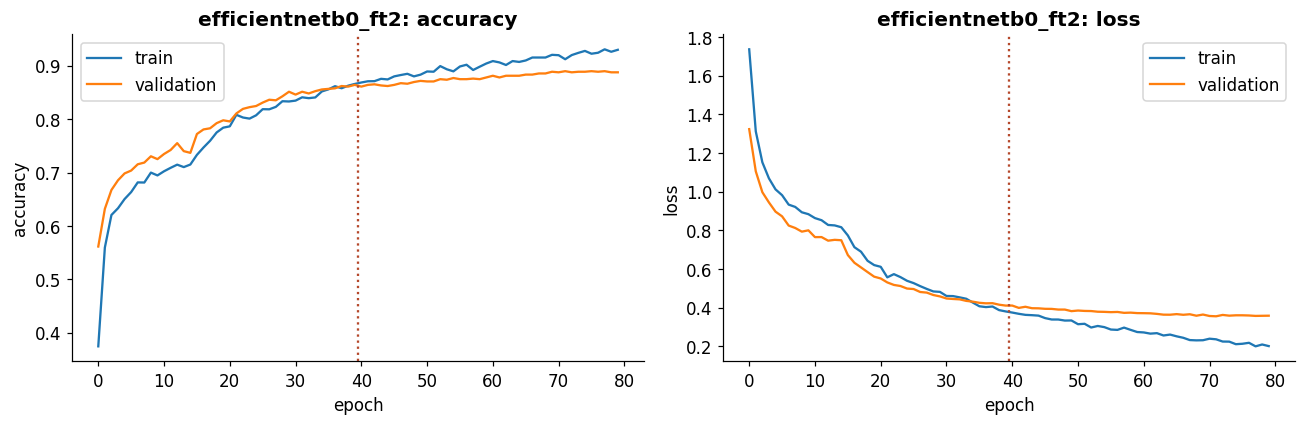

Experiment logged: efficientnetb0_ft2 -> {'train_accuracy': 0.9578, 'val_accuracy': 0.8898, 'test_accuracy': 0.8597, 'test_macro_f1': 0.8593, 'fit_time_s': 596.4, 'predict_ms_per_image': 7.045, 'n_params_millions': 4.06}


{'train_accuracy': 0.9578,
 'val_accuracy': 0.8898,
 'test_accuracy': 0.8597,
 'test_macro_f1': 0.8593,
 'fit_time_s': 596.4,
 'predict_ms_per_image': 7.045,
 'n_params_millions': 4.06}

In [12]:
NAME, SOURCE, N_UNFREEZE_2 = "efficientnetb0_ft2", "efficientnetb0", 100

if already_trained(NAME):
    effnet2 = keras.models.load_model(ku.model_path(NAME))
    print(f"Loaded existing {NAME}; training skipped")
    extra_time = float(pd.read_csv(ku.EXPERIMENTS_FILE).set_index("model").loc[NAME, "fit_time_s"])
else:
    keras.utils.set_random_seed(ku.SEED)
    effnet2 = keras.models.load_model(ku.model_path(SOURCE))
    # The pretrained base is the nested sub-model with the most layers
    base = max((l for l in effnet2.layers if isinstance(l, keras.Model)), key=lambda m: len(m.layers))
    unfreeze_top(base, N_UNFREEZE_2)
    print(f"Trainable weights now: {sum(np.prod(w.shape) for w in effnet2.trainable_weights) / 1e6:.2f}M")
    start = time.time()
    h3 = train_stage(effnet2, NAME, epochs=40, lr=1e-5, patience=8)
    extra_time = time.time() - start
    effnet2.save(ku.model_path(NAME))

    # Full training curve: earlier EfficientNetB0 history + this extra stage
    prev = pd.read_csv(os.path.join(PATHS["logs"], f"history_{SOURCE}.csv"), index_col=0)
    history = {k: prev[k].tolist() + [float(v) for v in h3.history[k]]
               for k in ["accuracy", "val_accuracy", "loss", "val_loss"]}
    ku.save_history(history, NAME, NOTEBOOK)
    fig = ku.plot_history(history, NAME, NOTEBOOK)
    for ax in fig.axes:
        ax.axvline(len(prev) - 0.5, color="#B5482B", linestyle=":")          # start of extended stage
    fig.savefig(os.path.join(PATHS["figures"], f"history_{NAME}.png"), dpi=300, bbox_inches="tight")
    plt.show()

ALL_RESULTS[NAME] = evaluate_and_log(effnet2, NAME, extra_time,
                                     params={"source": SOURCE, "unfrozen_layers": N_UNFREEZE_2,
                                             "lr": 1e-5, "epochs_max": 40},
                                     notes="continued fine-tuning of efficientnetb0; fit_time is the extra stage only")
ALL_RESULTS[NAME]

**Interpretation:** unfreezing 100 layers raised validation accuracy from **86.4% to 89.0%** (best at epoch 32 of the extra stage) and test accuracy from **84.9% to 86.0%** (macro-F1 0.859), in about 10 more minutes. The gain on the test set is real but smaller than on validation, because validation accuracy was used to pick the best epoch and is therefore slightly optimistic; the **test score is the honest estimate**. Training accuracy rose to 95.8%, so the train–test gap widened to about 10 points: more unfrozen layers fit the training signers more closely. Further fine-tuning would likely give diminishing returns.

## 7 · Deep learning vs classic machine learning
All models, classic and deep, are read from the shared `experiments.csv` and compared on the **same test set**.

In [13]:
exp = pd.read_csv(ku.EXPERIMENTS_FILE)
cols = ["model", "type", "train_accuracy", "val_accuracy", "test_accuracy", "test_macro_f1",
        "fit_time_s", "predict_ms_per_image", "n_params_millions"]
comparison = exp.reindex(columns=cols).sort_values("test_accuracy", ascending=False).reset_index(drop=True)
ku.save_table(comparison.round(4), "05_all_models_comparison", NOTEBOOK,
              caption="Test performance of all classic and deep-learning models.")
comparison.round(3)

Table saved  -> /content/drive/MyDrive/DSA4050/ksl-recognition/outputs/tables/05_all_models_comparison.csv


,model,type,train_accuracy,val_accuracy,test_accuracy,test_macro_f1,fit_time_s,predict_ms_per_image,n_params_millions
0,efficientnetb0_ft2,deep_learning,0.958,0.890,0.860,0.859,596.400,7.045,4.06
1,efficientnetb0,deep_learning,0.904,0.864,0.849,0.849,604.300,8.037,4.06
2,cnn_scratch,deep_learning,0.933,0.858,0.843,0.843,2506.000,5.448,1.18
3,mobilenetv2,deep_learning,0.934,0.844,0.816,0.817,446.900,4.237,2.27
4,hog+svm_rbf,classic_ml,1.000,0.634,0.600,0.603,19.985,1.350,NaN
5,hog+knn,classic_ml,0.643,0.584,0.558,0.558,1.249,0.130,NaN
6,hog+logreg,classic_ml,0.624,0.540,0.523,0.524,2.542,0.024,NaN
7,hog+random_forest,classic_ml,1.000,0.565,0.518,0.516,19.252,0.155,NaN
8,raw_pixels+svm_rbf,classic_ml,0.997,0.379,0.350,0.352,25.907,1.072,NaN
9,raw_pixels+knn,classic_ml,0.389,0.305,0.275,0.271,0.580,0.153,NaN


Figure saved -> /content/drive/MyDrive/DSA4050/ksl-recognition/outputs/figures/05_all_models_accuracy.png


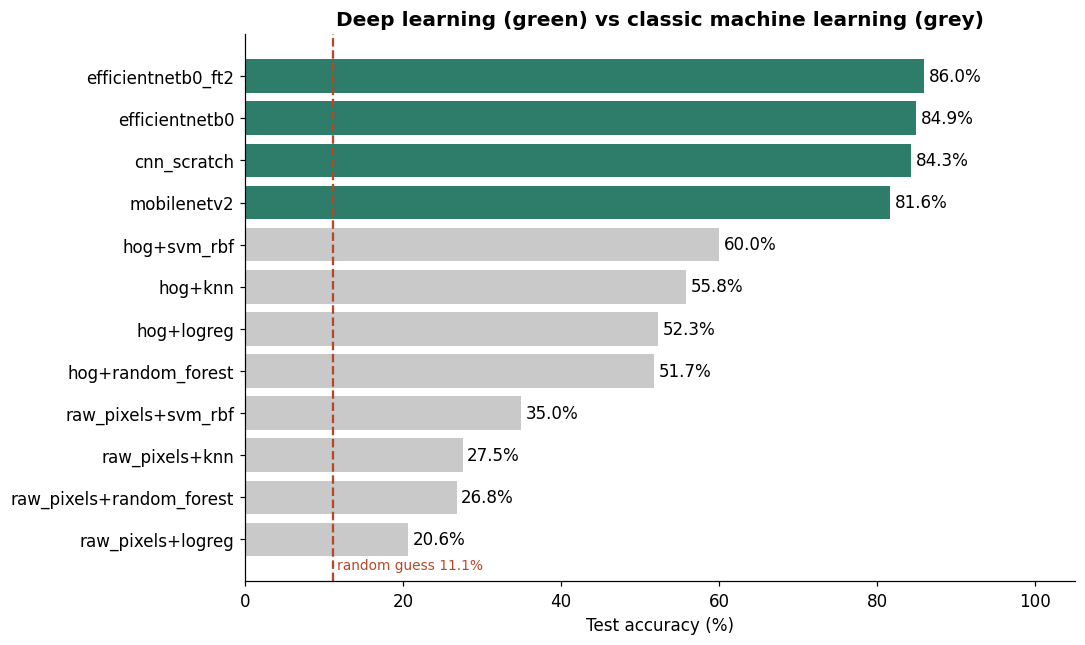

In [14]:
baseline = 1 / N_CLASSES
plot = comparison.sort_values("test_accuracy")
fig, ax = plt.subplots(figsize=(10, 6))
colours = ["#2E7D6B" if t == "deep_learning" else "#C9C9C9" for t in plot["type"]]
bars = ax.barh(plot["model"], plot["test_accuracy"] * 100, color=colours)
ax.bar_label(bars, labels=[f"{v:.1f}%" for v in plot["test_accuracy"] * 100], padding=3)
ax.axvline(baseline * 100, color="#B5482B", linestyle="--")
ax.text(baseline * 100 + 0.5, -0.7, f"random guess {baseline:.1%}", color="#B5482B", fontsize=9)
ax.set_xlim(0, 105)
ax.set_xlabel("Test accuracy (%)")
ax.set_title("Deep learning (green) vs classic machine learning (grey)")
fig.tight_layout()
ku.save_figure(fig, "05_all_models_accuracy", NOTEBOOK, caption="Test accuracy of every model, deep learning vs classic ML.")
plt.show()

## 8 · Save the best deep-learning model
The best model is chosen by **validation accuracy** (not test accuracy) and saved as `dl_best.keras` for notebook 06 and the dashboard.

In [15]:
dl = comparison[comparison["type"] == "deep_learning"].sort_values(
    ["val_accuracy", "test_macro_f1"], ascending=False)
best_name = dl.iloc[0]["model"]
best_model = keras.models.load_model(ku.model_path(best_name))
best_model.save(ku.model_path("dl_best"))

best_classic = comparison[comparison["type"] == "classic_ml"].sort_values("val_accuracy", ascending=False).iloc[0]
best_dl = dl.iloc[0]
ku.log_result("best_dl_model", best_name, NOTEBOOK)
ku.log_result("best_dl_test_accuracy", float(best_dl["test_accuracy"]), NOTEBOOK)
ku.log_result("best_dl_test_macro_f1", float(best_dl["test_macro_f1"]), NOTEBOOK)
ku.log_result("dl_vs_classic_gain_pts", round(100 * (best_dl["test_accuracy"] - best_classic["test_accuracy"]), 1), NOTEBOOK)
print(f"Best deep model : {best_name} ({best_dl['test_accuracy']:.1%} test accuracy)")
print(f"Best classic    : {best_classic['model']} ({best_classic['test_accuracy']:.1%})")
print(f"Gain            : {100 * (best_dl['test_accuracy'] - best_classic['test_accuracy']):+.1f} percentage points")

Result logged: best_dl_model = efficientnetb0_ft2
Result logged: best_dl_test_accuracy = 0.8597
Result logged: best_dl_test_macro_f1 = 0.8593
Result logged: dl_vs_classic_gain_pts = 25.9
Best deep model : efficientnetb0_ft2 (86.0% test accuracy)
Best classic    : hog+svm_rbf (60.0%)
Gain            : +25.9 percentage points


## Check · Project status

In [16]:
ku.project_summary()

Project root : /content/drive/MyDrive/DSA4050/ksl-recognition
Figures      : 21
Tables       : 14
Models       : 6
Results      : 45
Experiments  : 12


## Findings for the report
- **Deep learning clearly beats classic ML.** All four deep models reach **81.6–86.0% test accuracy**, against **60.0%** for the best classic model (HOG + SVM), a gain of **+25.9 percentage points** for the best model.
- **Best model: EfficientNetB0 with extended fine-tuning: 86.0% test accuracy, macro-F1 0.859** (validation 89.0%), 4.06M weights, about 7 ms per image on a T4 GPU.
- **A CNN from scratch is surprisingly competitive:** 84.3% with only 1.18M weights. Augmentation kept overfitting low (93% train vs 84% test, compared with 100% vs 60% for SVM), but it needed about **42 minutes** of training versus 7–10 minutes for the transfer models, and it had not fully converged after 60 epochs.
- **Transfer learning needs fine-tuning:** with frozen ImageNet features, accuracy plateaued around 68–74% on validation; unfreezing the top layers added 12–16 points. Unfreezing more layers (40 → 100) added a further 2.6 points on validation and 1.1 on test.
- **Trade-offs:** MobileNetV2 is the smallest and fastest pretrained model (81.6%, 2.27M weights) and suits phones; EfficientNetB0 is the most accurate.
- **Honest evaluation:** model choices used only the validation set; the test set was used once per model. Validation scores are 2–3 points above test scores, as expected when validation guides early stopping.

**Next notebook:** `06_evaluation.ipynb`: detailed evaluation of the best model: confusion matrix, per-sign results, misclassified examples, Grad-CAM heatmaps (where the model looks), and robustness to blur, darkness and rotation.